# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (PyTorch)

| Nama | NRP |
|------|-----|
| Sulaiman Faiz Tsaqib | 5054251048 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **PyTorch** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, torch, dll).
# Set random seed dengan torch.manual_seed(42) dan np.random.seed(42).
# Tentukan device: device = "cuda" if torch.cuda.is_available() else "cpu", lalu tampilkan device yang digunakan.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

torch.manual_seed(42)
np.random.seed(42)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

Device: cpu


In [2]:
# Load file fashion-mnist_train.csv dan fashion-mnist_test.csv.
# Setiap baris berisi 1 kolom label dan 784 kolom piksel (28×28) bernilai 0-255.
# Tampilkan ukuran data train dan test.
# Hanya fashion-mnist_test.csv yang tersedia, sehingga file ini dibagi menjadi data train (80%) dan test (20%)
df = pd.read_csv('fashion-mnist_test.csv')
train_df, test_df = train_test_split(df, test_size=0.2, stratify=df['label'], random_state=42)
print('Train:', train_df.shape)
print('Test :', test_df.shape)

Train: (8000, 785)
Test : (2000, 785)


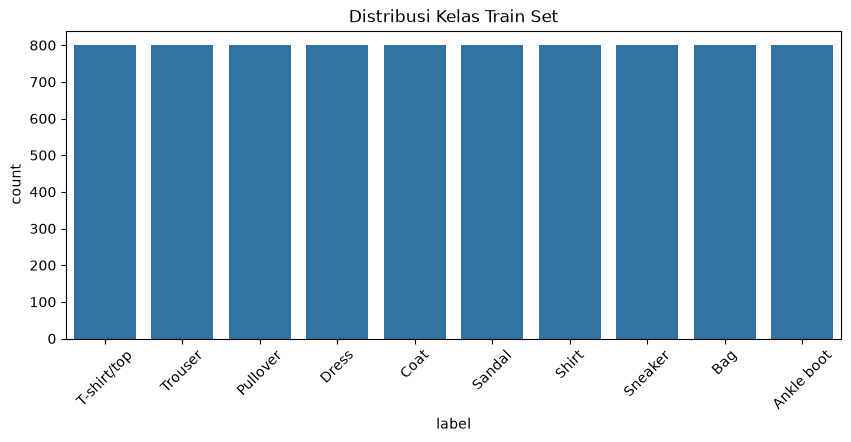

In [3]:
# Buat list atau dictionary yang memetakan label angka (0-9) ke nama kelas.
# Tampilkan distribusi kelas pada train set dalam bentuk bar plot.
classes = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

plt.figure(figsize=(10, 4))
sns.countplot(x=train_df['label'].map(dict(enumerate(classes))), order=classes)
plt.xticks(rotation=45)
plt.title('Distribusi Kelas Train Set')
plt.show()

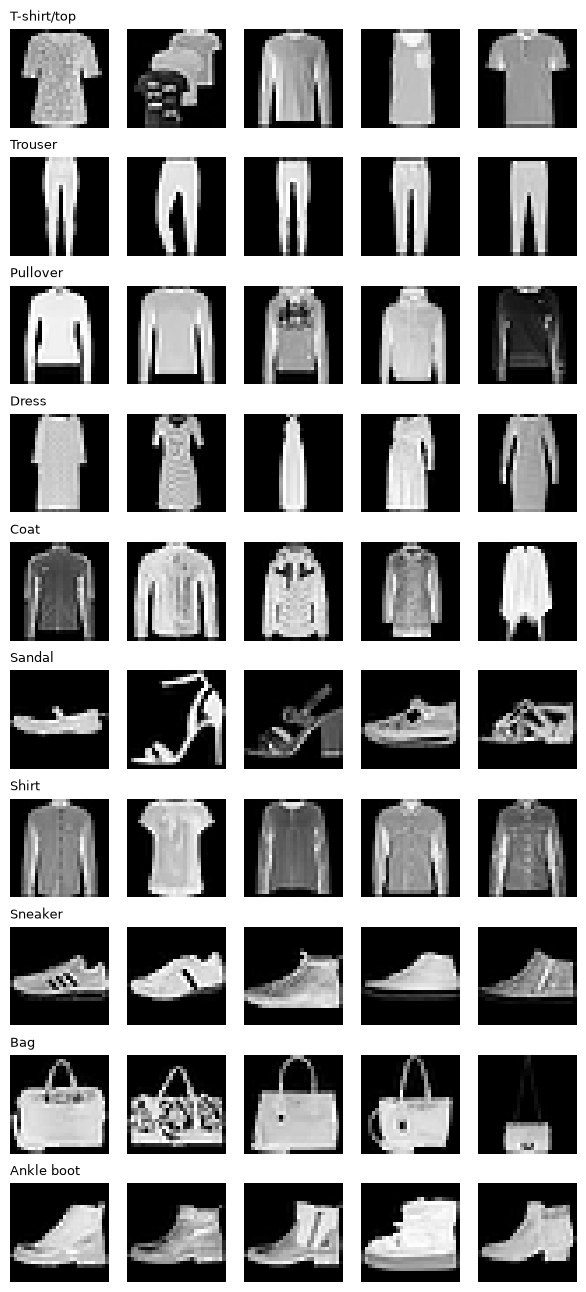

In [4]:
# Tampilkan contoh gambar dari setiap kelas (misalnya grid 10 kelas × 5 gambar) beserta nama kelasnya.
# Kelas mana saja yang secara visual terlihat mirip?
fig, ax = plt.subplots(10, 5, figsize=(6, 13))
for i in range(10):
    imgs = train_df[train_df['label'] == i].iloc[:5, 1:].values
    for j in range(5):
        ax[i, j].imshow(imgs[j].reshape(28, 28), cmap='gray')
        ax[i, j].axis('off')
    ax[i, 0].set_title(classes[i], fontsize=9, loc='left')
plt.tight_layout()
plt.show()

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

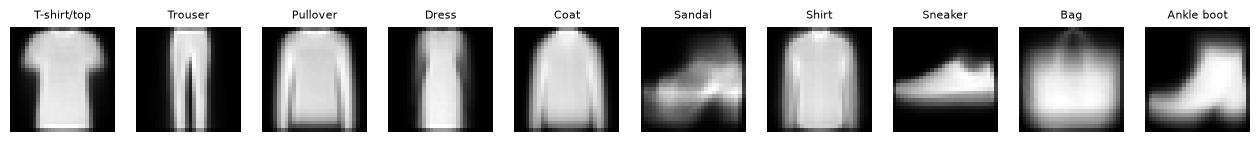

label
T-shirt/top    84.55
Trouser        57.79
Pullover       97.13
Dress          64.98
Coat           99.26
Sandal         35.87
Shirt          82.93
Sneaker        43.50
Bag            90.21
Ankle boot     75.54
dtype: float64


In [5]:
# Rata-rata gambar setiap kelas dan rata-rata intensitas piksel
fig, ax = plt.subplots(1, 10, figsize=(16, 2))
for i in range(10):
    ax[i].imshow(train_df[train_df['label'] == i].iloc[:, 1:].mean().values.reshape(28, 28), cmap='gray')
    ax[i].set_title(classes[i], fontsize=8)
    ax[i].axis('off')
plt.show()

print(train_df.iloc[:, 1:].mean(axis=1).groupby(train_df['label']).mean().rename(index=dict(enumerate(classes))).round(2))

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di PyTorch, urutan dimensi gambar adalah **(batch, channel, tinggi, lebar)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)`, atau `(N, 1, 28, 28)` dengan `nn.Flatten()` di awal model |
| CNN | `(N, 1, 28, 28)` |

In [6]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test.
X_train, y_train = train_df.drop(columns='label').values, train_df['label'].values
X_test, y_test = test_df.drop(columns='label').values, test_df['label'].values

In [7]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255).
X_train = X_train / 255.0
X_test = X_test / 255.0

In [8]:
# Bagi data train menjadi train set dan validation set (misalnya 90:10) dengan stratify=y.
# Test set dari file fashion-mnist_test.csv hanya digunakan untuk evaluasi akhir.
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.1, stratify=y_train, random_state=42)
print(X_train.shape, X_val.shape, X_test.shape)

(7200, 784) (800, 784) (2000, 784)


In [9]:
# Ubah data menjadi tensor: X bertipe torch.float32 dengan bentuk (N, 1, 28, 28), y bertipe torch.long (wajib untuk nn.CrossEntropyLoss).
# Buat DataLoader untuk train, validation, dan test menggunakan TensorDataset (shuffle=True hanya untuk train).
to_x = lambda a: torch.tensor(a, dtype=torch.float32).view(-1, 1, 28, 28)
to_y = lambda a: torch.tensor(a, dtype=torch.long)

batch_size = 64
train_loader = DataLoader(TensorDataset(to_x(X_train), to_y(y_train)), batch_size=batch_size, shuffle=True)
val_loader = DataLoader(TensorDataset(to_x(X_val), to_y(y_val)), batch_size=batch_size)
test_loader = DataLoader(TensorDataset(to_x(X_test), to_y(y_test)), batch_size=batch_size)

# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output** tanpa Softmax dan **`nn.CrossEntropyLoss`** sebagai loss function. Loss ini sudah menyertakan Softmax di dalamnya.

Contoh arsitektur: `Flatten → Linear(784, 256) → ReLU → Linear(256, 128) → ReLU → Linear(128, 10)`

In [10]:
# Definisikan arsitektur ANN sebagai class turunan nn.Module, lalu pindahkan ke device dengan model.to(device).
# Tampilkan arsitektur model dengan print(model) dan jumlah parameternya: sum(p.numel() for p in model.parameters()).
class ANN(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256), nn.ReLU(),
            nn.Linear(256, 128), nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)

n_params = lambda m: sum(p.numel() for p in m.parameters())

ann = ANN().to(device)
print(ann)
print('Jumlah parameter:', n_params(ann))

ANN(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 235146


In [11]:
# Tentukan loss function (nn.CrossEntropyLoss), optimizer, learning rate, jumlah epoch, dan batch size.
# Tulis training loop. Setiap batch harus dipindahkan ke device yang sama dengan model (x.to(device), y.to(device)).
# Di akhir setiap epoch, hitung loss dan accuracy train dan validation (gunakan model.eval() dan torch.no_grad()), simpan ke dictionary history.
# Disarankan membuat training loop dalam bentuk fungsi agar dapat digunakan ulang pada 3.2 dan 3.3.
loss_fn = nn.CrossEntropyLoss()

def evaluate(model, loader):
    model.eval()
    total_loss, correct = 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x)
            total_loss += loss_fn(out, y).item() * len(y)
            correct += (out.argmax(dim=1) == y).sum().item()
    n = len(loader.dataset)
    return total_loss / n, correct / n

def train(model, epochs=15, lr=1e-3):
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history = {'loss': [], 'acc': [], 'val_loss': [], 'val_acc': []}
    for epoch in range(epochs):
        model.train()
        for x, y in train_loader:
            x, y = x.to(device), y.to(device)
            loss = loss_fn(model(x), y)
            opt.zero_grad()
            loss.backward()
            opt.step()
        for key, loader in [('', train_loader), ('val_', val_loader)]:
            l, a = evaluate(model, loader)
            history[key + 'loss'].append(l)
            history[key + 'acc'].append(a)
        print(f"Epoch {epoch + 1:2d} | loss {history['loss'][-1]:.4f} acc {history['acc'][-1]:.4f} | "
              f"val_loss {history['val_loss'][-1]:.4f} val_acc {history['val_acc'][-1]:.4f}")
    return history

hist_ann = train(ann)

Epoch  1 | loss 0.5676 acc 0.8107 | val_loss 0.6188 val_acc 0.7925


Epoch  2 | loss 0.4731 acc 0.8332 | val_loss 0.5502 val_acc 0.8187


Epoch  3 | loss 0.4259 acc 0.8485 | val_loss 0.5046 val_acc 0.8375


Epoch  4 | loss 0.4140 acc 0.8475 | val_loss 0.4900 val_acc 0.8200


Epoch  5 | loss 0.3713 acc 0.8643 | val_loss 0.4605 val_acc 0.8375


Epoch  6 | loss 0.3576 acc 0.8692 | val_loss 0.4691 val_acc 0.8438


... (5 outputs left out)

Epoch 12 | loss 0.2410 acc 0.9082 | val_loss 0.4158 val_acc 0.8625


Epoch 13 | loss 0.2288 acc 0.9131 | val_loss 0.4302 val_acc 0.8638


Epoch 14 | loss 0.2319 acc 0.9108 | val_loss 0.4613 val_acc 0.8413


Epoch 15 | loss 0.2065 acc 0.9208 | val_loss 0.4044 val_acc 0.8612


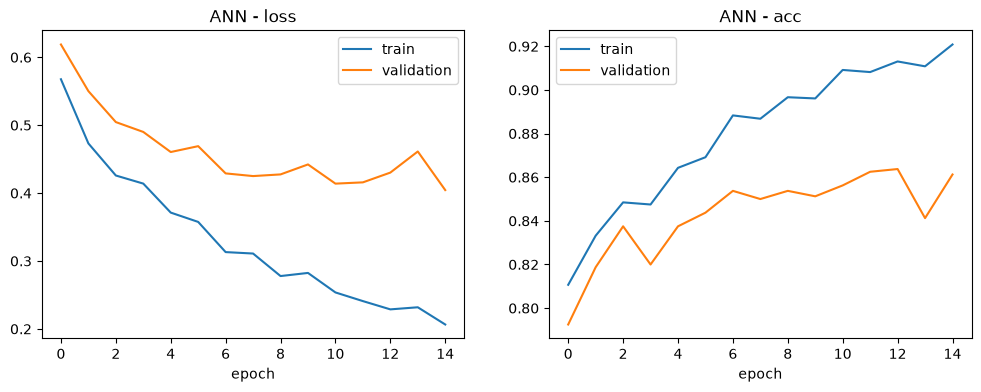

In [12]:
# Tampilkan learning curve (loss dan accuracy) train vs validation.
def plot_history(h, title):
    fig, ax = plt.subplots(1, 2, figsize=(12, 4))
    for a, m in zip(ax, ['loss', 'acc']):
        a.plot(h[m], label='train')
        a.plot(h['val_' + m], label='validation')
        a.set_title(f'{title} - {m}')
        a.set_xlabel('epoch')
        a.legend()
    plt.show()

plot_history(hist_ann, 'ANN')

In [13]:
# Lakukan prediksi pada test set dengan model.eval() dan torch.no_grad().
# Ambil kelas dengan nilai output terbesar menggunakan argmax(dim=1). Simpan hasil prediksi label dalam bentuk numpy array.
def predict(model, loader):
    model.eval()
    with torch.no_grad():
        return torch.cat([model(x.to(device)).argmax(dim=1).cpu() for x, _ in loader]).numpy()

y_pred_ann = predict(ann, test_loader)

## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2d → ReLU → MaxPool2d, lalu dilanjutkan Flatten dan Linear.

Contoh arsitektur: `[Conv2d(1, 32, 3, padding=1) → ReLU → MaxPool2d(2)] → [Conv2d(32, 64, 3, padding=1) → ReLU → MaxPool2d(2)] → Flatten → Linear(64×7×7, 128) → ReLU → Linear(128, 10)`

In [14]:
# Definisikan arsitektur CNN sederhana sebagai class turunan nn.Module (gunakan nn.Conv2d, nn.MaxPool2d, nn.Flatten, dan nn.Linear).
# Tampilkan arsitektur model beserta jumlah parameternya.
# Hitung secara manual ukuran output setiap layer konvolusi dan pooling menggunakan rumus (W - K + 2P) / S + 1.
# Hasil perhitungan ini menentukan ukuran input nn.Linear pertama setelah Flatten (channel × tinggi × lebar).
# Cocokkan dengan mengirim satu tensor dummy torch.zeros(1, 1, 28, 28) ke bagian konvolusi dan cetak bentuk outputnya.
# Perhitungan manual (W - K + 2P) / S + 1:
# Conv1  : (28 - 3 + 2) / 1 + 1 = 28 -> (32, 28, 28)
# Pool1  : (28 - 2) / 2 + 1     = 14 -> (32, 14, 14)
# Conv2  : (14 - 3 + 2) / 1 + 1 = 14 -> (64, 14, 14)
# Pool2  : (14 - 2) / 2 + 1     = 7  -> (64, 7, 7)
# Flatten: 64 x 7 x 7 = 3136
class CNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

cnn = CNN().to(device)
print(cnn)
print('Jumlah parameter:', n_params(cnn))
print('Output features:', cnn.features(torch.zeros(1, 1, 28, 28).to(device)).shape)

CNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 421642
Output features: torch.Size([1, 64, 7, 7])


Epoch  1 | loss 0.5888 acc 0.7721 | val_loss 0.6166 val_acc 0.7525


Epoch  2 | loss 0.4500 acc 0.8335 | val_loss 0.4925 val_acc 0.8175


Epoch  3 | loss 0.4390 acc 0.8419 | val_loss 0.4906 val_acc 0.8313


Epoch  4 | loss 0.4264 acc 0.8329 | val_loss 0.4826 val_acc 0.8275


Epoch  5 | loss 0.3145 acc 0.8888 | val_loss 0.3815 val_acc 0.8650


Epoch  6 | loss 0.3000 acc 0.8922 | val_loss 0.3682 val_acc 0.8675


... (5 outputs left out)

Epoch 12 | loss 0.1804 acc 0.9382 | val_loss 0.3381 val_acc 0.8825


Epoch 13 | loss 0.1737 acc 0.9390 | val_loss 0.3111 val_acc 0.8938


Epoch 14 | loss 0.2414 acc 0.9019 | val_loss 0.4081 val_acc 0.8638


Epoch 15 | loss 0.1552 acc 0.9411 | val_loss 0.3505 val_acc 0.8838


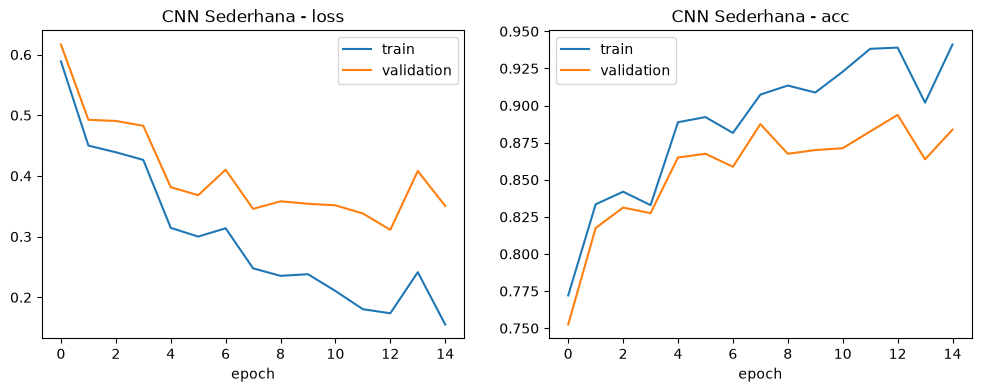

In [15]:
# Latih model dengan pengaturan yang sama seperti 3.1 agar perbandingan adil.
# Tampilkan learning curve train vs validation.
hist_cnn = train(cnn)
plot_history(hist_cnn, 'CNN Sederhana')

In [16]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.
y_pred_cnn = predict(cnn, test_loader)

## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [17]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout.
# Urutan yang umum: nn.Conv2d -> nn.BatchNorm2d(jumlah_channel_output) -> nn.ReLU -> nn.MaxPool2d.
# Tambahkan nn.Dropout(p) sebelum layer output.
# Ingat: BatchNorm dan Dropout berperilaku berbeda saat training dan evaluasi, pastikan memanggil model.train() dan model.eval() di tempat yang tepat.
# Tampilkan arsitektur model beserta jumlah parameternya.
class CNN_BN(nn.Module):
    def __init__(self, p=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Dropout(p),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

cnn_bn = CNN_BN().to(device)
print(cnn_bn)
print('Jumlah parameter:', n_params(cnn_bn))

CNN_BN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (classifier): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=3136, out_features=128, bias=True)
    (2): ReLU()
    (3): Dropout(p=0.5, inplace=False)
    (4): Linear(in_features=128, out_features=10, bias=True)
  )
)
Jumlah parameter: 421834


Epoch  1 | loss 0.4614 acc 0.8276 | val_loss 0.5096 val_acc 0.8225


Epoch  2 | loss 0.3874 acc 0.8531 | val_loss 0.4306 val_acc 0.8500


Epoch  3 | loss 0.3283 acc 0.8776 | val_loss 0.3796 val_acc 0.8588


Epoch  4 | loss 0.2861 acc 0.8904 | val_loss 0.3545 val_acc 0.8725


Epoch  5 | loss 0.2563 acc 0.9049 | val_loss 0.3295 val_acc 0.8875


Epoch  6 | loss 0.2170 acc 0.9203 | val_loss 0.3087 val_acc 0.8888


... (5 outputs left out)

Epoch 12 | loss 0.1308 acc 0.9544 | val_loss 0.3149 val_acc 0.9025


Epoch 13 | loss 0.1165 acc 0.9565 | val_loss 0.3095 val_acc 0.9038


Epoch 14 | loss 0.1285 acc 0.9506 | val_loss 0.3166 val_acc 0.9075


Epoch 15 | loss 0.1143 acc 0.9572 | val_loss 0.3447 val_acc 0.8962


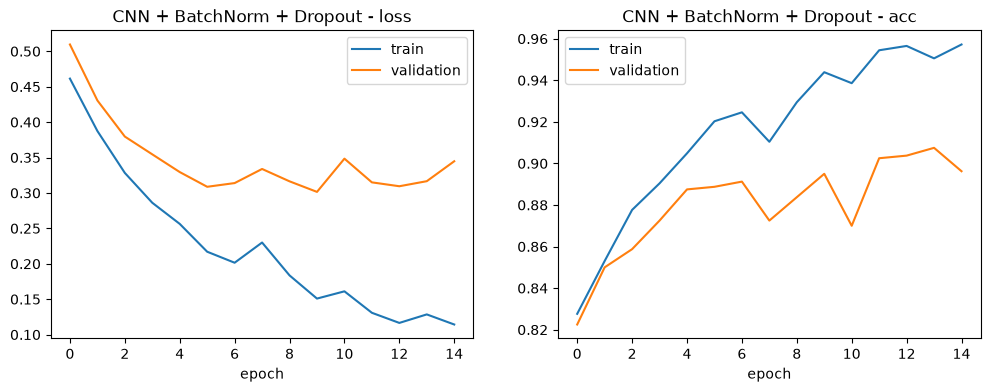

In [18]:
# Latih model dengan pengaturan yang sama seperti 3.2.
# Tampilkan learning curve train vs validation.
# Perhatikan selisih antara train dan validation dibandingkan dengan model 3.2.
hist_cnn_bn = train(cnn_bn)
plot_history(hist_cnn_bn, 'CNN + BatchNorm + Dropout')

In [19]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.
y_pred_cnn_bn = predict(cnn_bn, test_loader)

# 4. Evaluasi Model

In [20]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score (macro average),
# beserta jumlah parameter setiap model. Sajikan dalam satu tabel perbandingan.
models = {'ANN': (ann, y_pred_ann), 'CNN Sederhana': (cnn, y_pred_cnn), 'CNN + BN + Dropout': (cnn_bn, y_pred_cnn_bn)}
results = pd.DataFrame({
    name: {
        'Accuracy': accuracy_score(y_test, p),
        'Precision': precision_score(y_test, p, average='macro'),
        'Recall': recall_score(y_test, p, average='macro'),
        'F1-Score': f1_score(y_test, p, average='macro'),
        'Parameter': n_params(m),
    } for name, (m, p) in models.items()
}).T
best_name = results['Accuracy'].idxmax()
best_model, best_pred = models[best_name]
print('Model terbaik:', best_name)
results

Model terbaik: CNN + BN + Dropout


,Accuracy,Precision,Recall,F1-Score,Parameter
ANN,0.8525,0.852453,0.8525,0.851734,235146.0
CNN Sederhana,0.8740,0.886211,0.8740,0.875968,421642.0
CNN + BN + Dropout,0.8850,0.887349,0.8850,0.883865,421834.0


In [21]:
# Tampilkan classification report (metrik per kelas) untuk model terbaik.
print(classification_report(y_test, best_pred, target_names=classes, digits=4))

              precision    recall  f1-score   support

 T-shirt/top     0.8018    0.8900    0.8436       200
     Trouser     0.9801    0.9850    0.9825       200
    Pullover     0.8968    0.6950    0.7831       200
       Dress     0.9316    0.8850    0.9077       200
        Coat     0.7669    0.9050    0.8303       200
      Sandal     0.9340    0.9900    0.9612       200
       Shirt     0.7090    0.6700    0.6889       200
     Sneaker     0.9385    0.9150    0.9266       200
         Bag     0.9608    0.9800    0.9703       200
  Ankle boot     0.9541    0.9350    0.9444       200

    accuracy                         0.8850      2000
   macro avg     0.8873    0.8850    0.8839      2000
weighted avg     0.8873    0.8850    0.8839      2000



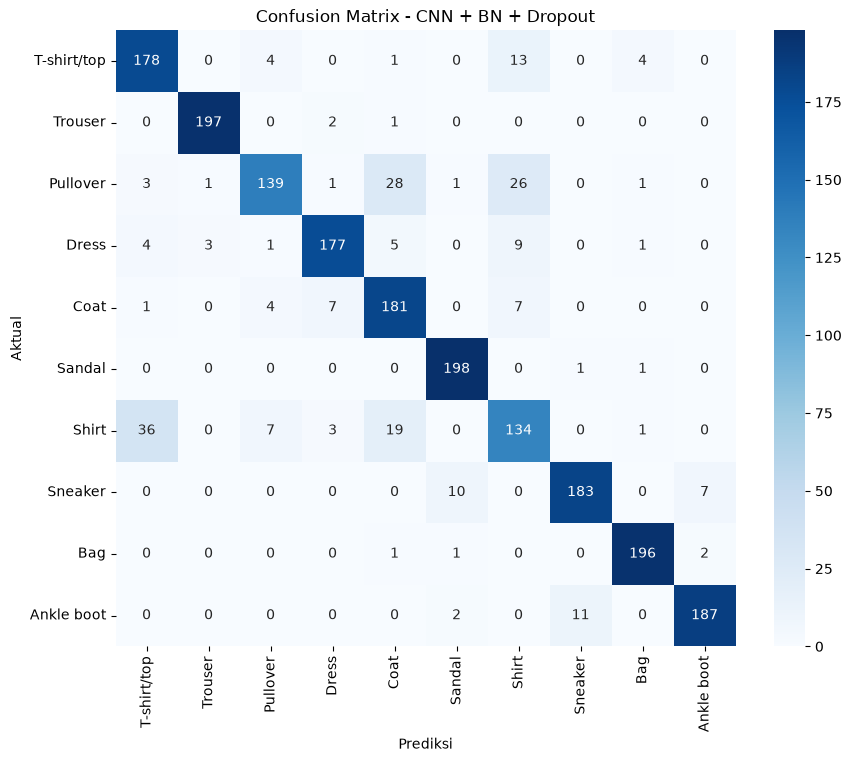

In [22]:
# Tampilkan Confusion Matrix 10×10 model terbaik dalam bentuk heatmap, gunakan nama kelas sebagai label sumbu.
# Pasangan kelas mana yang paling sering tertukar?
plt.figure(figsize=(10, 8))
sns.heatmap(confusion_matrix(y_test, best_pred), annot=True, fmt='d', cmap='Blues', xticklabels=classes, yticklabels=classes)
plt.xlabel('Prediksi')
plt.ylabel('Aktual')
plt.title(f'Confusion Matrix - {best_name}')
plt.show()

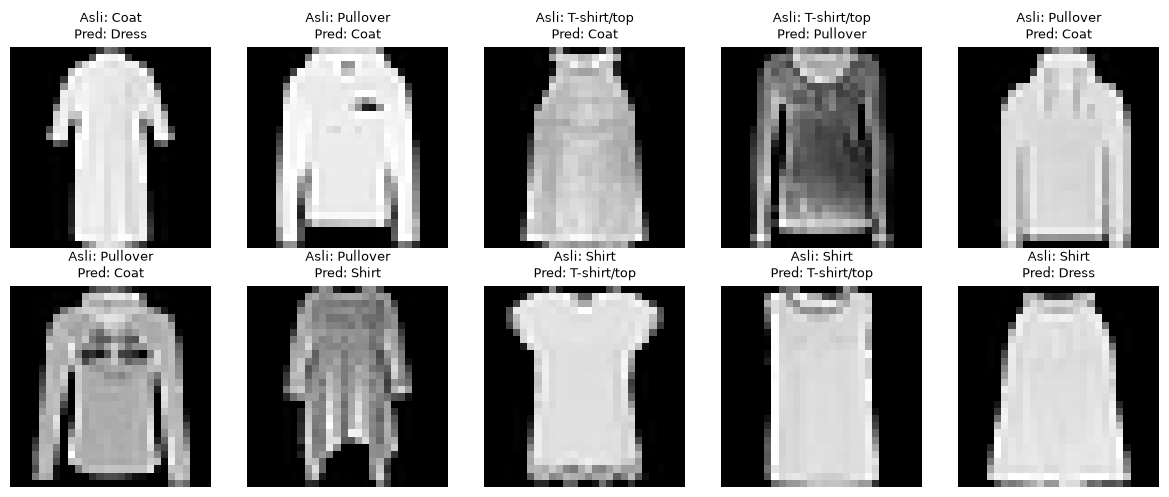

In [23]:
# Tampilkan beberapa contoh gambar yang salah diklasifikasikan oleh model terbaik,
# beserta label asli dan label prediksinya.
wrong = np.where(best_pred != y_test)[0][:10]
fig, ax = plt.subplots(2, 5, figsize=(12, 5))
for a, i in zip(ax.ravel(), wrong):
    a.imshow(X_test[i].reshape(28, 28), cmap='gray')
    a.set_title(f'Asli: {classes[y_test[i]]}\nPred: {classes[best_pred[i]]}', fontsize=9)
    a.axis('off')
plt.tight_layout()
plt.show()

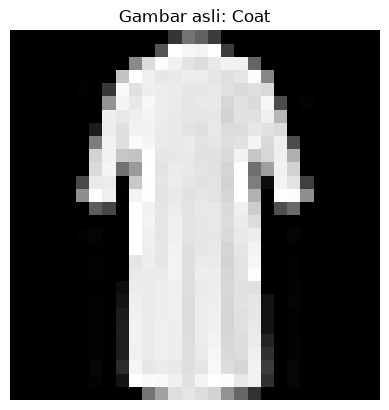

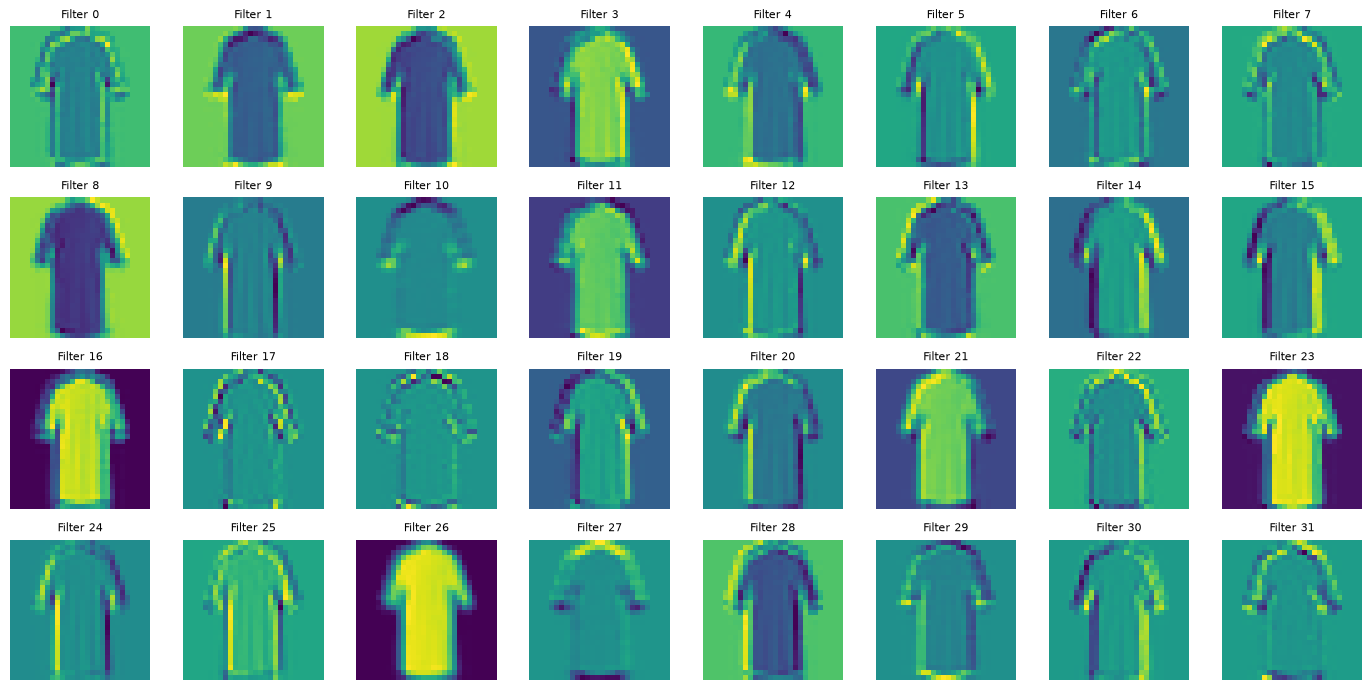

In [24]:
# Visualisasikan feature map dari layer konvolusi pertama model terbaik untuk satu gambar contoh.
# Kirim satu gambar (bentuk (1, 1, 28, 28)) ke layer konvolusi pertama saja, misalnya model.features[0](x) jika menggunakan nn.Sequential bernama features,
# lalu tampilkan setiap channel output-nya sebagai gambar (gunakan .detach().cpu().numpy()).
# Apa saja pola yang ditangkap oleh masing-masing filter?
x = to_x(X_test[:1]).to(device)
best_model.eval()
with torch.no_grad():
    fmap = best_model.features[0](x).detach().cpu().numpy()[0]

plt.imshow(X_test[0].reshape(28, 28), cmap='gray')
plt.title(f'Gambar asli: {classes[y_test[0]]}')
plt.axis('off')
plt.show()

fig, ax = plt.subplots(4, 8, figsize=(14, 7))
for i, a in enumerate(ax.ravel()):
    a.imshow(fmap[i], cmap='viridis')
    a.set_title(f'Filter {i}', fontsize=8)
    a.axis('off')
plt.tight_layout()
plt.show()

In [25]:
# Simpan bobot model terbaik dengan torch.save(model.state_dict(), "model.pth").
# Model ini akan digunakan kembali pada tugas Deployment, jadi simpan juga definisi class model kalian.
torch.save(best_model.state_dict(), 'model.pth')
print('Bobot model disimpan:', best_name)

Bobot model disimpan: CNN + BN + Dropout


In [26]:
%%writefile model.py
import torch.nn as nn


class CNN_BN(nn.Module):
    def __init__(self, p=0.5):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(1, 32, 3, padding=1), nn.BatchNorm2d(32), nn.ReLU(), nn.MaxPool2d(2),
            nn.Conv2d(32, 64, 3, padding=1), nn.BatchNorm2d(64), nn.ReLU(), nn.MaxPool2d(2)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(64 * 7 * 7, 128), nn.ReLU(),
            nn.Dropout(p),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.classifier(self.features(x))

Overwriting model.py


# 5. Analisis

### Jelaskan secara detail hasil analisis yang didapatkan dari eksperimen yang telah dilakukan. Bandingkan performa ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout berdasarkan hasil evaluasi. Kaitkan perbedaan performa dengan jumlah parameter dan cara masing-masing model memproses gambar. Bahas pula pengaruh Batch Normalization dan Dropout terhadap learning curve, serta kelas-kelas yang sulit dibedakan oleh model. Pastikan analisis didasari oleh hasil eksperimen sendiri yang telah dilakukan.

**Catatan data:** hanya file `fashion-mnist_test.csv` (10.000 gambar) yang tersedia, sehingga data dibagi menjadi 7.200 train, 800 validation, dan 2.000 test (stratified, setiap kelas seimbang). Training dilakukan selama 15 epoch dengan Adam (lr = 0.001) dan batch size 64 untuk ketiga model.

**Hasil evaluasi pada test set (macro average):**

| Model | Accuracy | Precision | Recall | F1-Score | Parameter |
|---|---|---|---|---|---|
| ANN | 0.8525 | 0.8525 | 0.8525 | 0.8517 | 235.146 |
| CNN Sederhana | 0.8740 | 0.8862 | 0.8740 | 0.8760 | 421.642 |
| CNN + BN + Dropout | **0.8850** | **0.8873** | **0.8850** | **0.8839** | 421.834 |

1. **ANN vs CNN.** CNN sederhana unggul sekitar 2.2 poin accuracy dibanding ANN. ANN mem-flatten gambar menjadi 784 nilai sehingga informasi letak piksel yang bertetangga hilang, dan setiap piksel harus dipelajari secara terpisah. CNN memakai filter 3×3 yang sama (weight sharing) di seluruh gambar untuk mendeteksi pola lokal seperti tepi, kerah, dan lengan. MaxPooling membuat pola tersebut tetap terdeteksi walaupun posisinya sedikit bergeser.

2. **Kaitan dengan jumlah parameter.** CNN memiliki parameter lebih banyak (±422 ribu vs ±235 ribu). Namun bagian konvolusinya hanya memiliki 18.816 parameter. Sebagian besar parameter (±401 ribu) ada di layer `Linear(3136, 128)`. Jadi keunggulan CNN berasal dari cara memproses gambar, bukan dari banyaknya parameter. CNN + BN + Dropout hanya menambah 192 parameter (gamma dan beta BatchNorm), tetapi menjadi model terbaik.

3. **Pengaruh Batch Normalization dan Dropout terhadap learning curve.** BatchNorm mempercepat konvergensi: val accuracy pada epoch pertama 0.8225, dibanding 0.7525 (CNN sederhana) dan 0.7925 (ANN). Val loss terendahnya juga paling kecil (0.3015 vs 0.3111 pada CNN dan 0.4044 pada ANN), dan kurvanya lebih stabil dibanding CNN sederhana yang sempat melonjak pada epoch 7 dan 14. Meski begitu, ketiga model tetap menunjukkan tanda overfitting: selisih train dan validation accuracy di akhir training sekitar 6% (ANN 0.921 vs 0.861, CNN 0.941 vs 0.884, CNN+BN 0.957 vs 0.896). Pada CNN + BN + Dropout, val loss mulai naik setelah epoch ±10 sementara train loss terus turun. Hal ini wajar karena data train hanya 7.200 gambar. Dropout 0.5 menahan overfitting sehingga performa validation dan test tetap yang tertinggi, tetapi belum cukup untuk menutup selisihnya.

4. **Kelas yang sulit dibedakan.** Berdasarkan classification report, kelas dengan F1 terendah adalah **Shirt** (0.6889), **Pullover** (0.7831), **Coat** (0.8303), dan **T-shirt/top** (0.8436). Pasangan yang paling sering tertukar pada confusion matrix:
   - Shirt → T-shirt/top (36 gambar) dan T-shirt/top → Shirt (13)
   - Pullover → Coat (28) dan Pullover → Shirt (26)
   - Shirt → Coat (19)
   - Ankle boot → Sneaker (11) dan Sneaker → Sandal (10)

   Pakaian atas memiliki siluet yang hampir sama pada resolusi 28×28 grayscale (badan persegi dengan lengan). Pembedanya hanya detail kecil seperti kancing, kerah, atau resleting, dan detail tersebut mudah hilang. Contoh gambar yang salah klasifikasi memperlihatkan hal ini, misalnya kemeja lengan pendek yang terlihat seperti kaos. Sebaliknya, Trouser, Bag, dan Sandal memiliki bentuk yang khas sehingga F1-nya di atas 0.96.

5. **Feature map.** Filter pada layer konvolusi pertama sudah mempelajari pola dasar. Beberapa filter (misalnya 16, 23, 26) aktif pada seluruh area pakaian sehingga berfungsi seperti detektor siluet. Filter lain (misalnya 0, 9, 14, 24) menyorot tepi vertikal kiri atau kanan, sedangkan filter 17, 18, dan 27 menyorot tepi atas/horizontal seperti bahu dan kerah. Pola-pola sederhana ini kemudian digabungkan oleh layer berikutnya menjadi fitur yang lebih kompleks.

# 6. Kesimpulan dan Saran

### Berikan kesimpulan dari eksperimen yang telah dilakukan. Saran dapat berupa rekomendasi untuk eksperimen selanjutnya, perbaikan model, atau hal-hal lain yang relevan dengan tugas ini.

1. CNN lebih cocok untuk klasifikasi gambar dibanding ANN biasa karena mempertahankan struktur spasial gambar. Accuracy naik dari 0.8525 (ANN) ke 0.8740 (CNN sederhana).
2. Penambahan Batch Normalization dan Dropout menghasilkan model terbaik (accuracy 0.8850, F1 macro 0.8839) dengan tambahan parameter yang sangat kecil. Training juga lebih cepat konvergen dan lebih stabil. Model ini disimpan sebagai `model.pth` beserta definisi class-nya di `model.py`.
3. Kesalahan terbesar terjadi pada kelas pakaian atas yang mirip secara visual (Shirt, T-shirt/top, Pullover, Coat). Kelas Shirt adalah yang paling sulit.
4. Ketiga model masih overfitting (selisih train dan validation ±6%) karena data latih terbatas.

**Saran:**
- Menggunakan data train lengkap Fashion-MNIST (60.000 gambar), karena pada eksperimen ini hanya 7.200 gambar yang dipakai untuk training.
- Menambahkan data augmentation (random shift, horizontal flip), weight decay, dan early stopping berdasarkan validation loss untuk mengurangi overfitting.
- Mencoba arsitektur yang lebih dalam (3 blok konvolusi atau lebih), Dropout di antara blok konvolusi, serta learning rate scheduler.
- Menambah fokus pada kelas yang sulit, misalnya dengan melihat lebih banyak contoh salah klasifikasi pada kelas Shirt.